In [ ]:
import tensorflow as tf
import zipfile

url = "https://storage.googleapis.com/tensorflow-1-public/course2/cats_and_dogs_filtered.zip"
arquivo = tf.keras.utils.get_file("gatos_cachorros_infoeste.zip", origin=url)

with zipfile.ZipFile(arquivo) as zipado:
    zipado.extractall("/content")

68606236/68606236 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
pasta = "/content/cats_and_dogs_filtered/"

treino = tf.keras.utils.image_dataset_from_directory(
    pasta + "train", image_size=(64, 64), batch_size=32
)
validacao = tf.keras.utils.image_dataset_from_directory(
    pasta + "validation", image_size=(64, 64), batch_size=32, shuffle=False
)

classes = treino.class_names
print("Nossos animais:", classes)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Nossos animais: ['cats', 'dogs']


In [ ]:
modelo = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),
    tf.keras.layers.Rescaling(1/255),
    tf.keras.layers.Conv2D(16, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(2, activation="softmax")
])

In [ ]:
modelo.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

historico = modelo.fit(treino, validation_data=validacao, epochs=15)

Epoch 1/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 60ms/step - accuracy: 0.5460 - loss: 0.6927 - val_accuracy: 0.5000 - val_loss: 0.6933
Epoch 2/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.5980 - loss: 0.6666 - val_accuracy: 0.6630 - val_loss: 0.6377
Epoch 3/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.6815 - loss: 0.6155 - val_accuracy: 0.6190 - val_loss: 0.6247
Epoch 4/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.7130 - loss: 0.5658 - val_accuracy: 0.6550 - val_loss: 0.6117
Epoch 5/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.7430 - loss: 0.5200 - val_accuracy: 0.6940 - val_loss: 0.5850
Epoch 6/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.7700 - loss: 0.4883 - val_accuracy: 0.6760 - val_loss: 0.5946
Epoch 7/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.7905 - loss: 0.4645 - val_accuracy: 0.6560 - val_loss: 0.6200
Epoch 8/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.7770 - loss: 0.4576 - val_accuracy: 0.6940 - v

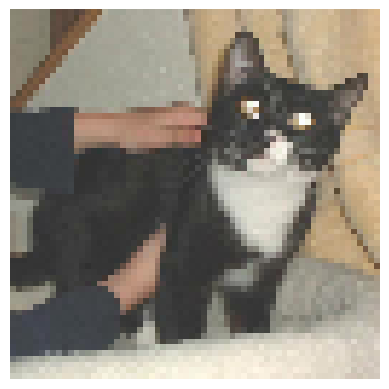

Resposta correta: cats
Resposta da IA: cats


In [ ]:
import matplotlib.pyplot as plt

for imagens, respostas in validacao.take(1):
    plt.imshow(imagens[0].numpy().astype("uint8"))
    plt.axis("off")
    plt.show()

    previsao = modelo.predict(imagens[:1], verbose=0)[0]
    print("Resposta correta:", classes[int(respostas[0])])
    print("Resposta da IA:", classes[previsao.argmax()])

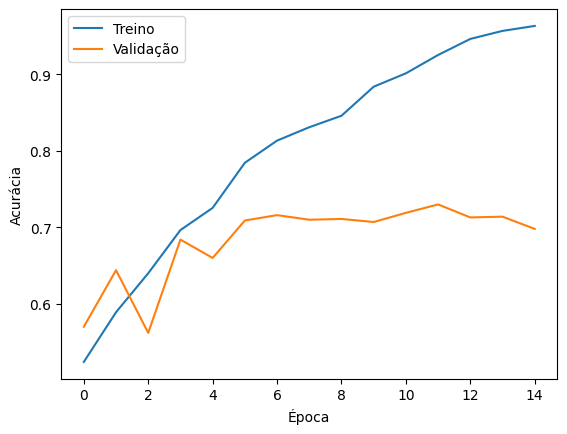

In [ ]:
plt.plot(historico.history["accuracy"], label="Treino")
plt.plot(historico.history["val_accuracy"], label="Validação")
plt.xlabel("Época")
plt.ylabel("Acurácia")
plt.legend()
plt.show()

Saving f36bf1ea2b2ecc2970014d5408875488.jpg to f36bf1ea2b2ecc2970014d5408875488.jpg


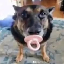

A IA escolheu: dogs


In [ ]:
from google.colab import files
from IPython.display import display

arquivos = files.upload()
nome = list(arquivos.keys())[0]

foto = tf.keras.utils.load_img(nome, target_size=(64, 64))
display(foto)

imagem = tf.keras.utils.img_to_array(foto)
imagem = tf.expand_dims(imagem, 0)
previsao = modelo.predict(imagem, verbose=0)[0]
print("A IA escolheu:", classes[previsao.argmax()])